# 04 — Experiment-calibrated MMM: closing the "MMM gap"

Three geo lift tests (Social → Paid Search → Programmatic DSP) each answered one question, in one window, in a few
geos. Always-on budgeting needs a **national, cross-channel, saturation-aware** answer. This notebook:

1. fits a Bayesian weekly MMM (PyMC: geometric adstock + Hill per channel, trend, Fourier seasonality, holidays) **without** the tests,
2. fits it again **with** one lift-test likelihood term per test arm,
3. scores both against the simulator's ground truth (ROI, marginal ROI, response curves),
4. triangulates last-touch vs experiment vs MMM vs truth,
5. turns the calibrated posterior into a budget reallocation, ±20% scenarios, and a *next test* recommendation.

*Synthetic data — illustrative magnitudes only.* Everything here is produced by `incrlab.mmm` (`python -m incrlab.mmm` writes
the same outputs to `reports/`).

In [1]:
import logging, warnings, json
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(message)s")
for n in ("pymc", "pytensor", "arviz"):
    logging.getLogger(n).setLevel(logging.ERROR)
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from incrlab.mmm.pipeline import run, roi_table, triangulation_table, calibration_fit_table
from incrlab.mmm import figures as F, report
from incrlab.mmm.model import PRIORS
FIG = "../reports/figures/mmm/"


## 1. Calibration inputs: where each test's number comes from

`load_calibration_inputs()` reads `reports/results/{meta,search,dsp}.json → extra.incremental_per_dollar` (incremental **sales**
per $ removed in the test window), validates the schema (channels, window, leakage, SE > 0, metric = sales), and logs the source
per test. Only if a module's output is missing does it fall back to the stub in `data/calibration_inputs.json` — and the readout,
JSON and every chart footer say so loudly.

In [2]:
S = run()   # full settings: 4 chains x 500 draws per fit (~2 min); includes a sensitivity fit
print("sources:", json.dumps(S.sources, indent=1))
print("STUB tests:", S.stub_tests or "none - all calibration inputs are real module readouts")
cal = calibration_fit_table(S)
(cal[["test", "arm", "channels", "observed_ipd", "se", "truth_ipd", "uncalibrated_ipd", "calibrated_ipd"]]
   .assign(**{c: lambda d, c=c: d[c] * 1000 for c in ["observed_ipd", "se", "truth_ipd", "uncalibrated_ipd", "calibrated_ipd"]})
   .round(2).rename(columns=lambda c: c.replace("_ipd", " /$1k")))

calibration input meta   <- reports/results/meta.json


calibration input search <- reports/results/search.json


calibration input dsp_a  <- reports/results/dsp.json


calibration input dsp_b  <- reports/results/dsp.json


[mmm] uncalibrated fit: 32s, r-hat 1.009, ESS 1428, divergences 2


[mmm] calibrated fit: 31s, r-hat 1.010, ESS 1237, divergences 5


[mmm] calibrated_powered fit: 23s, r-hat 1.008, ESS 667, divergences 0


sources: {
 "meta": "reports/results/meta.json",
 "search": "reports/results/search.json",
 "dsp_a": "reports/results/dsp.json",
 "dsp_b": "reports/results/dsp.json"
}
STUB tests: none - all calibration inputs are real module readouts


,test,arm,channels,observed /$1k,se,truth /$1k,uncalibrated /$1k,calibrated /$1k
0,meta,holdout,social,1.76,2.99,1.71,1.23,1.28
1,search,branded_only,search_brand,1.65,3.72,1.09,0.75,0.75
2,search,all_search,search_nonbrand,-1.05,1.81,0.77,0.55,0.48
3,dsp_a,holdout,dsp_a,2.52,0.86,1.57,1.92,1.98
4,dsp_b,holdout,dsp_b,3.10,3.30,0.05,0.39,0.41


### How the calibration term works

For every posterior draw θ, the model replays each test: cut the arm's channel(s) to the test's leakage level during the window,
re-run adstock + Hill, and compute the incremental sales lost per $ removed — `ipd_model(θ)`. Then

`observed_ipd ~ Normal(ipd_model(θ), sqrt(SE_test² + (10% · observed)²))`.

This is preferable to turning a test into a prior on one coefficient: a test measures a **window-average return at the current
spend level**, which depends jointly on amplitude, half-saturation, slope *and* carry-over; leakage and multi-channel arms
(e.g. the all-search dark-out) are handled exactly; the 10% term absorbs geo→national transport error.

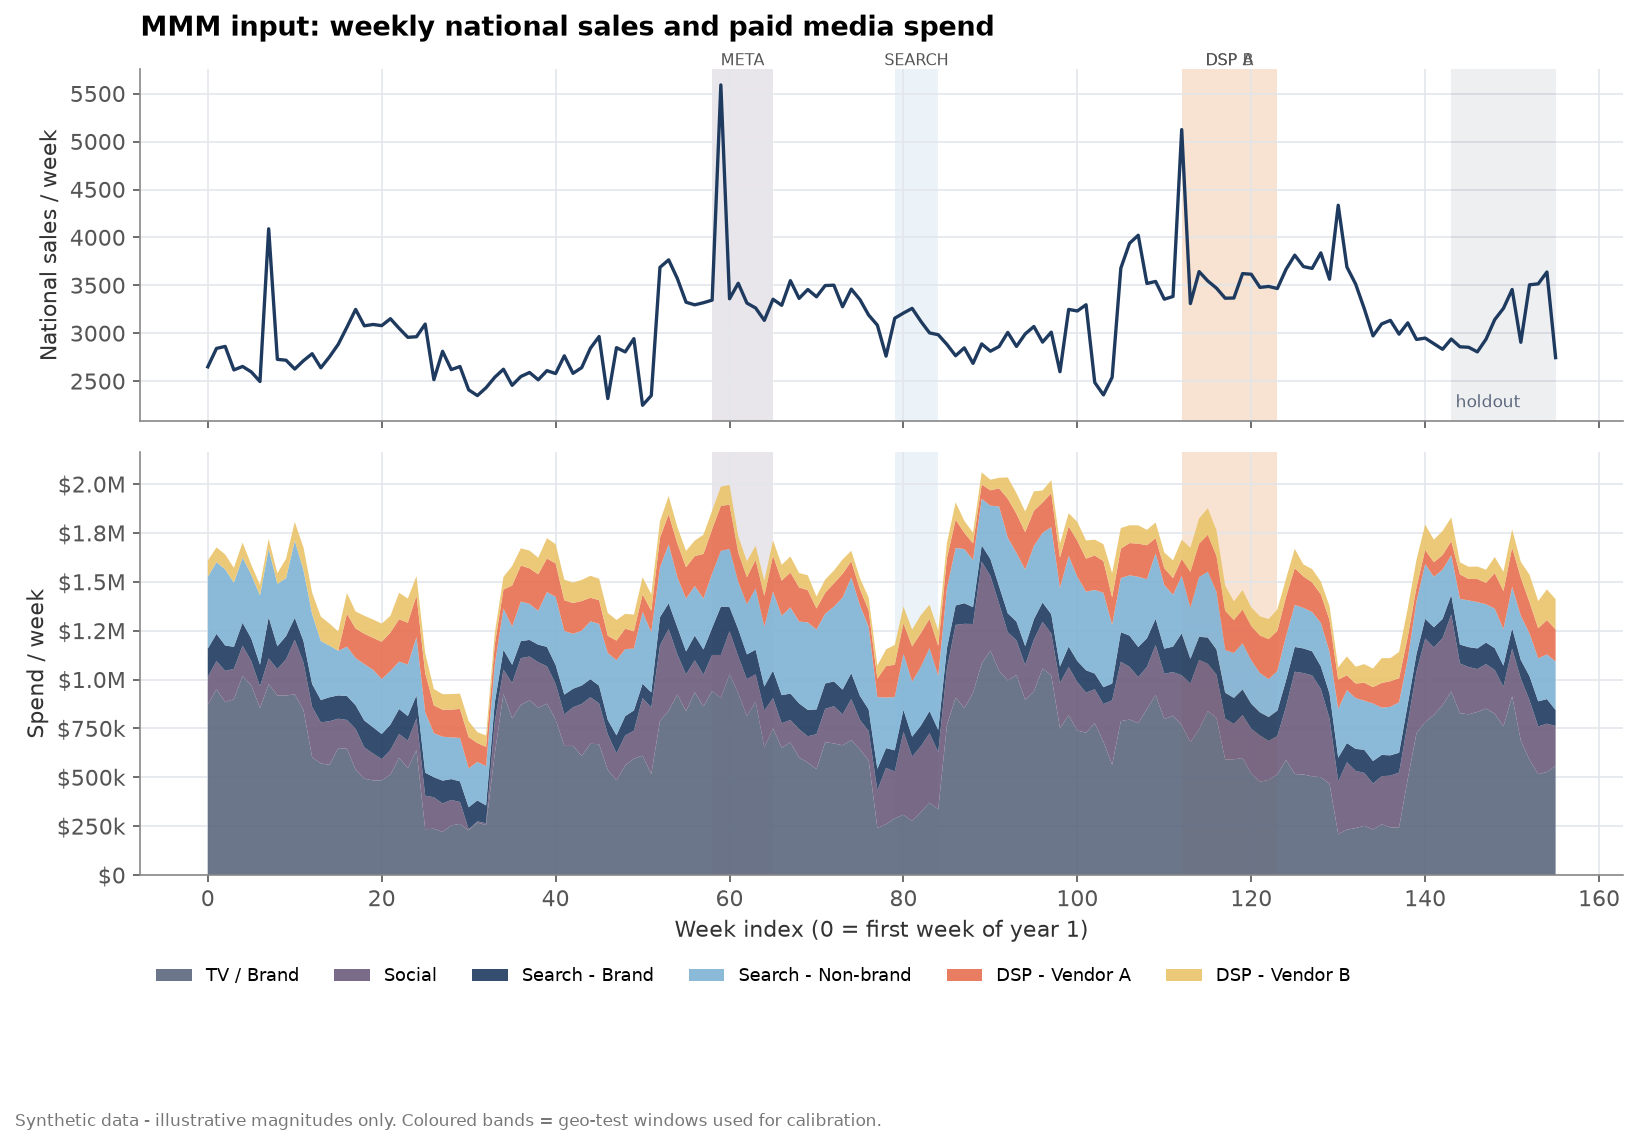

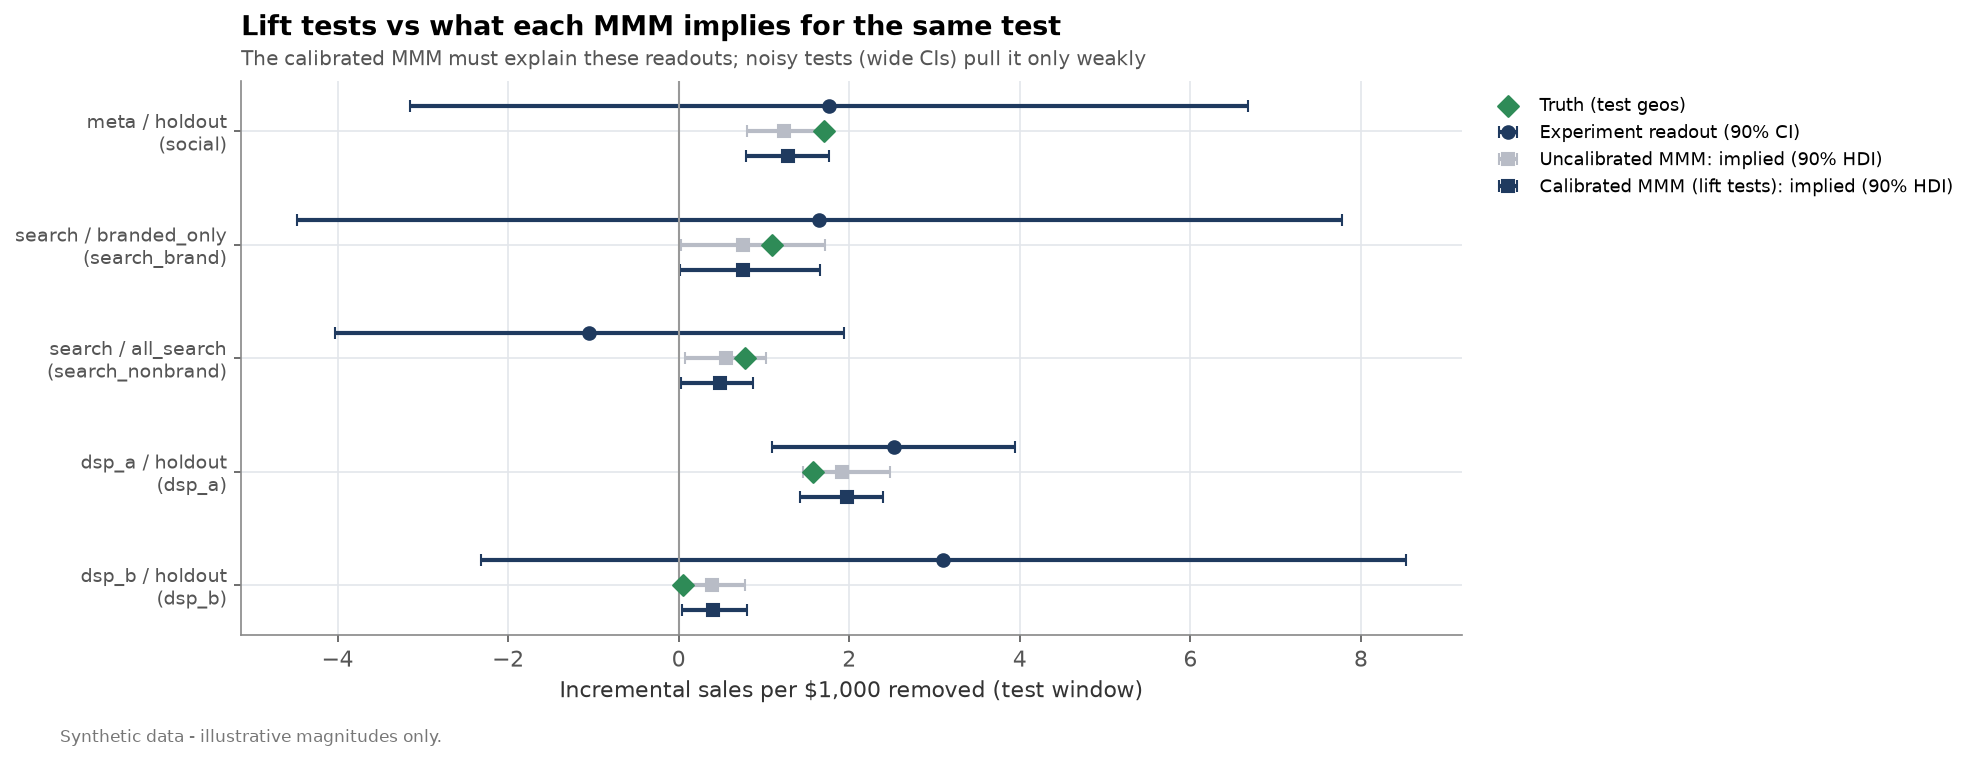

roi         LogNormal(log 1.0, 0.9) per channel (Meridian-...
decay       Beta(2, 2.5) per channel (mean 0.44; anything ...
half_sat    LogNormal(log 0.9, 0.5) x channel mean spend (...
slope       LogNormal(log 1.2, 0.25) (Hill shape: concave ...
baseline    intercept N(log mean y, 0.5); trend N(0, 0.2);...
sigma                            HalfNormal(0.1) on log sales
dtype: str

In [3]:
display(Image(FIG + "01_data_overview.png")); display(Image(FIG + "02_calibration_inputs.png"))
pd.Series(PRIORS)

## 2. Diagnostics

Convergence (r-hat, ESS, divergences), in-sample fit, and a **13-week true holdout** (never seen by either fit).

In [4]:
pd.DataFrame({n: {k: v for k, v in f.diag.items() if not k.startswith("_")} for n, f in S.fits.items()}).T.round(3)

,max_r_hat,min_ess_bulk,min_ess_tail,divergences,n_samples,divergence_rate,train_mape,train_r2,train_ppc_coverage90,train_weeks,holdout_mape,holdout_r2,holdout_ppc_coverage90,holdout_weeks
uncalibrated,1.009,1427.555,1127.264,2.0,2000.0,0.001,0.027,0.937,0.958,143.0,0.037,0.824,1.000,13.0
calibrated,1.010,1236.802,1154.228,5.0,2000.0,0.002,0.027,0.936,0.965,143.0,0.036,0.832,1.000,13.0
calibrated_powered,1.008,667.195,707.816,0.0,2000.0,0.000,0.027,0.937,0.951,143.0,0.041,0.784,0.923,13.0


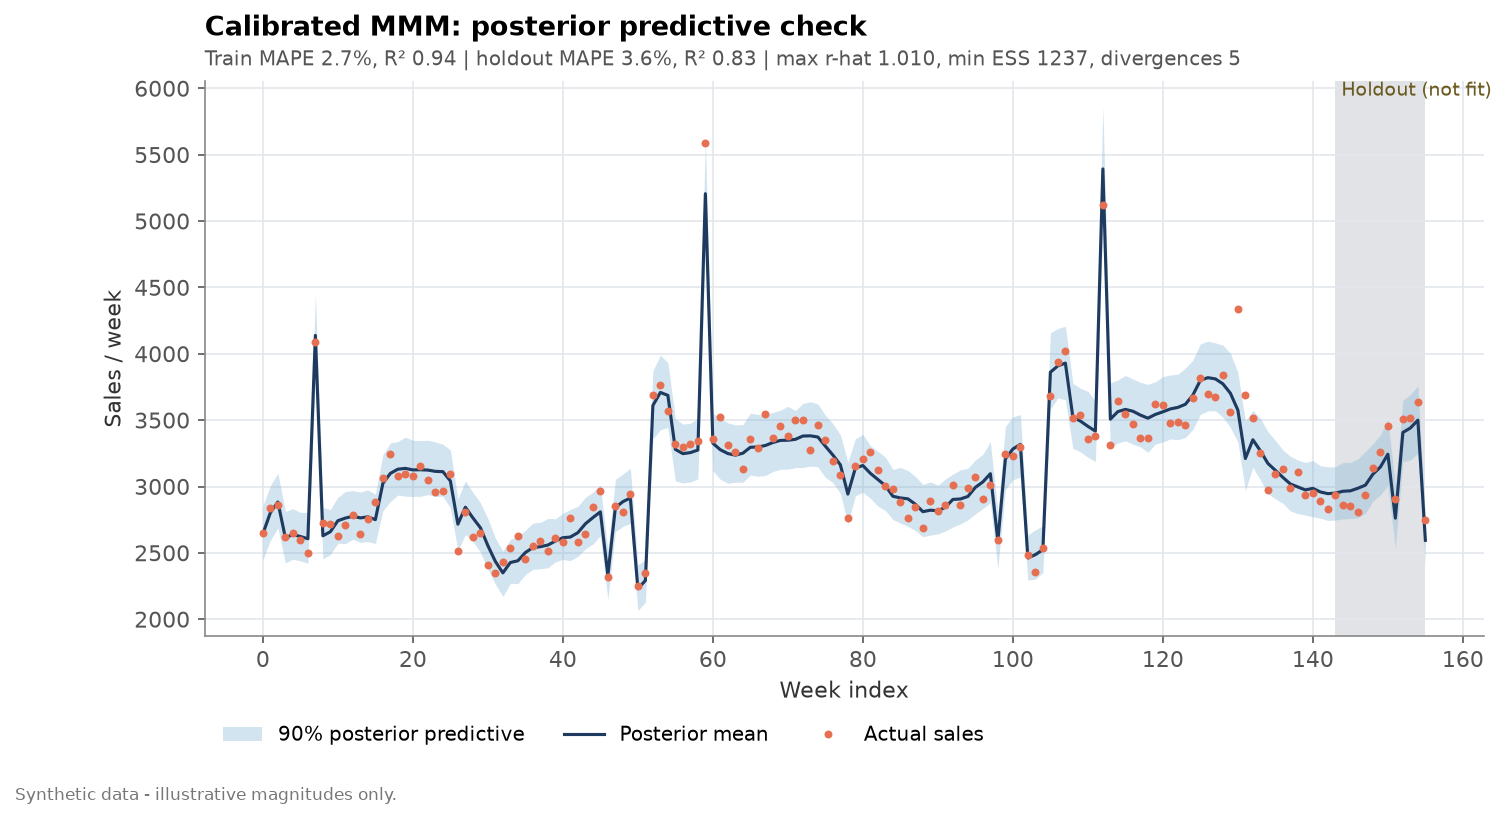

In [5]:
display(Image(FIG + "03_fit_ppc.png"))

## 3. Does calibration recover the TRUE ROI?

In [6]:
t = roi_table(S)
cols = ["channel", "true_roi"] + [c for c in t.columns if c.endswith(("_roi", "_roi_abs_err")) and not c.startswith("true")]
t[cols].round(2)

,channel,true_roi,uncalibrated_roi,uncalibrated_roi_abs_err,calibrated_roi,calibrated_roi_abs_err,calibrated_powered_roi,calibrated_powered_roi_abs_err
0,tv,0.45,0.42,0.04,0.42,0.04,0.35,0.11
1,social,1.63,1.95,0.32,2.02,0.39,2.37,0.74
2,search_brand,1.79,1.41,0.38,1.43,0.36,2.31,0.52
3,search_nonbrand,1.26,0.97,0.30,0.85,0.41,1.44,0.18
4,dsp_a,3.89,3.39,0.50,3.44,0.45,3.31,0.58
5,dsp_b,0.08,0.68,0.60,0.72,0.64,0.12,0.05


Mean |ROI error|  uncalibrated 0.36  ->  calibrated 0.38  (sensitivity, well-powered tests: 0.36)
channels improved by calibration: ['search_brand', 'dsp_a']


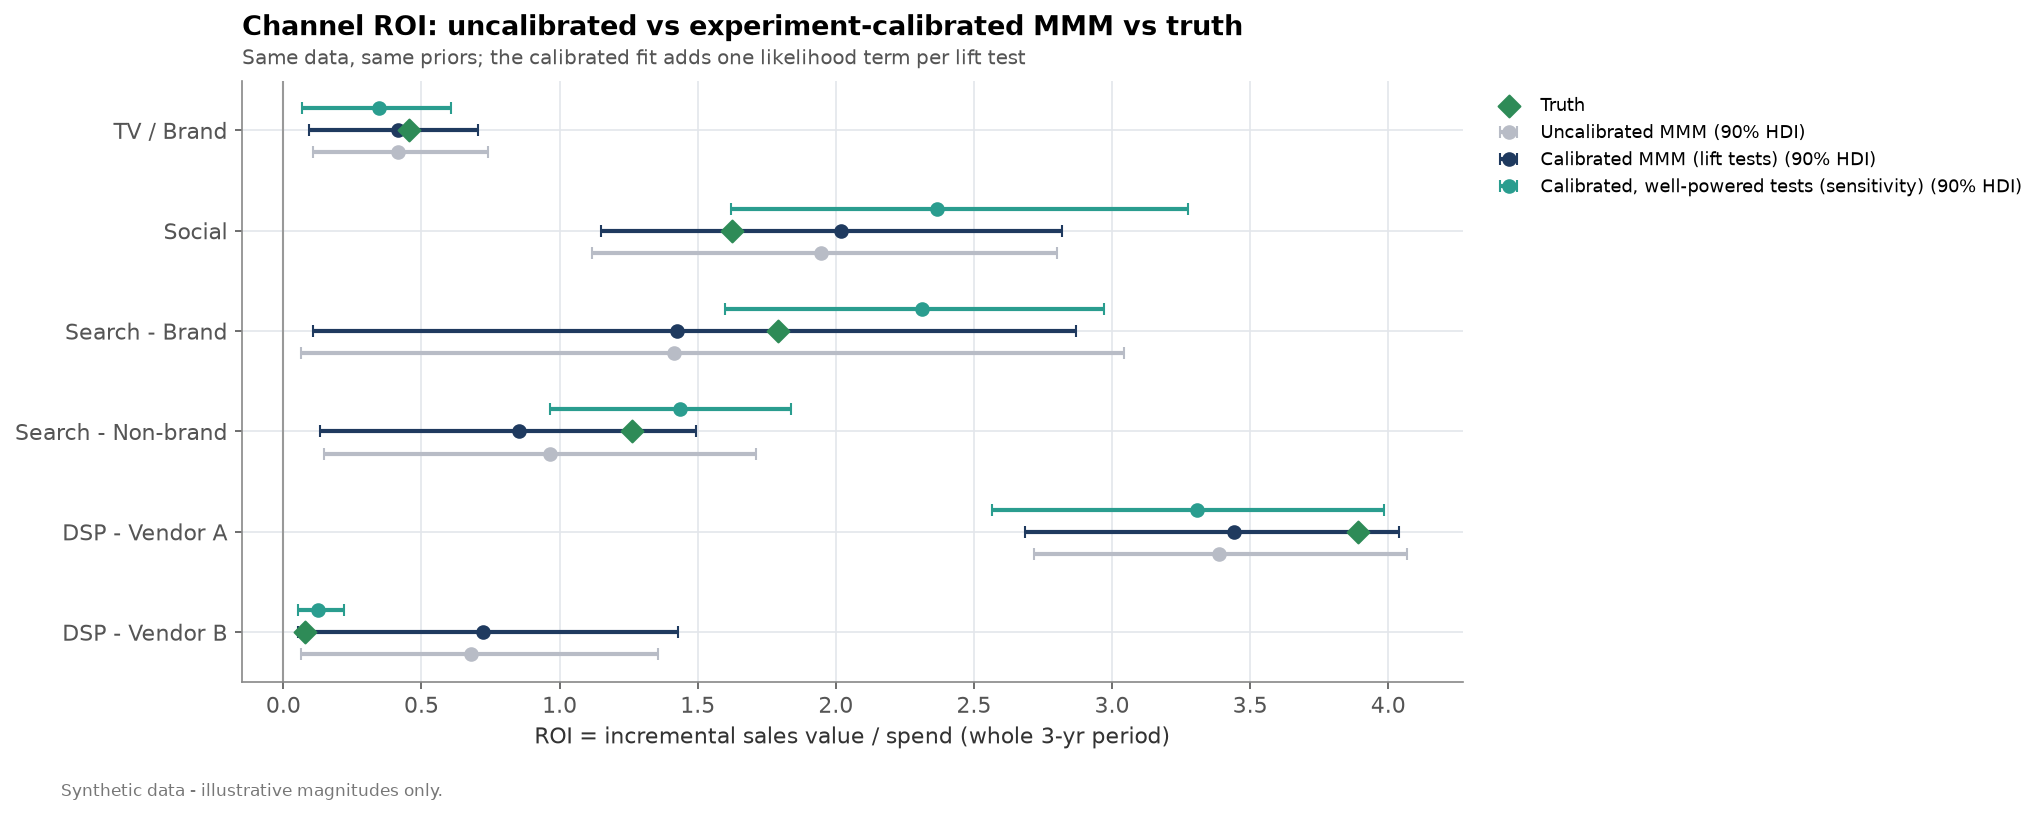

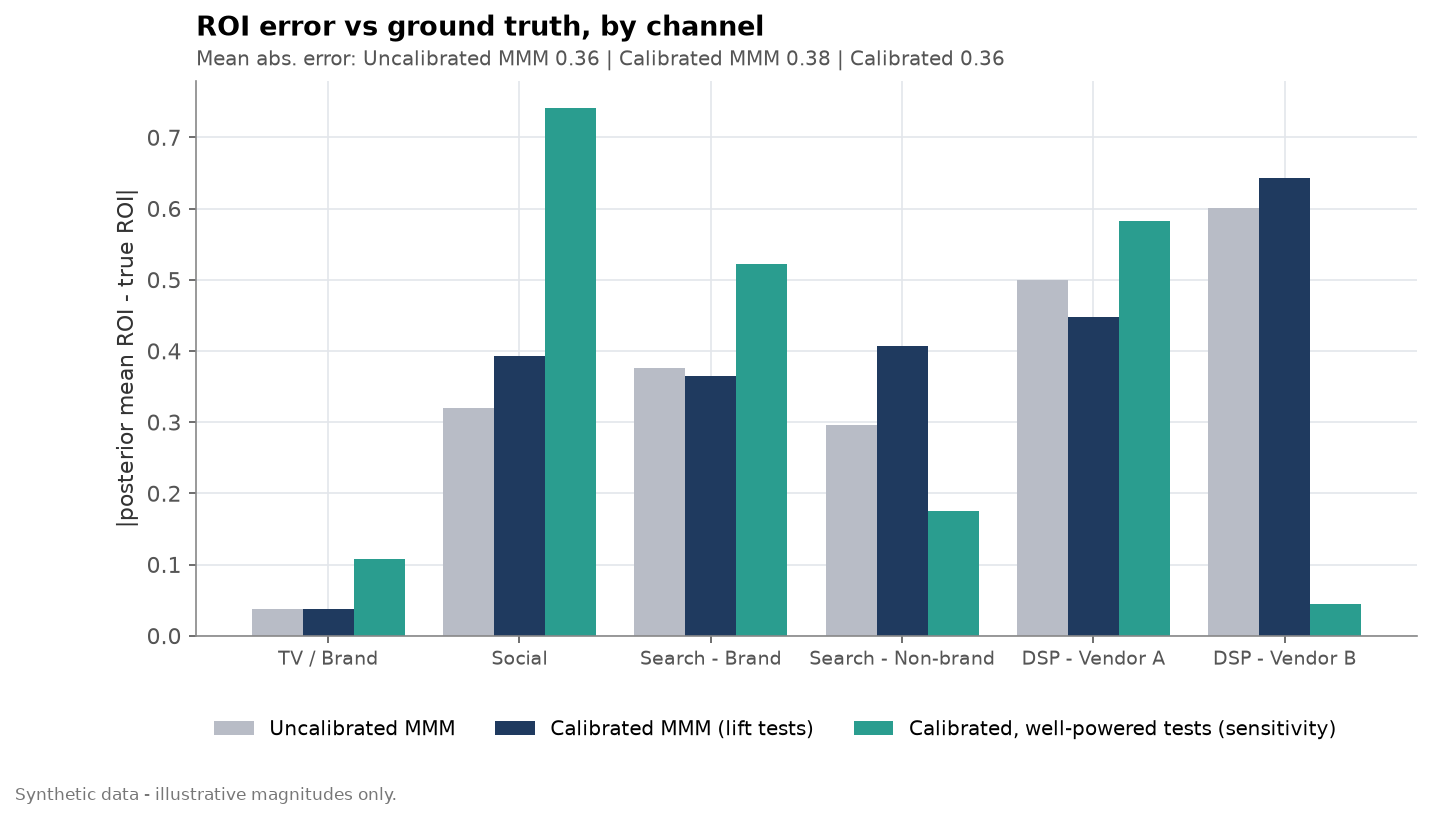

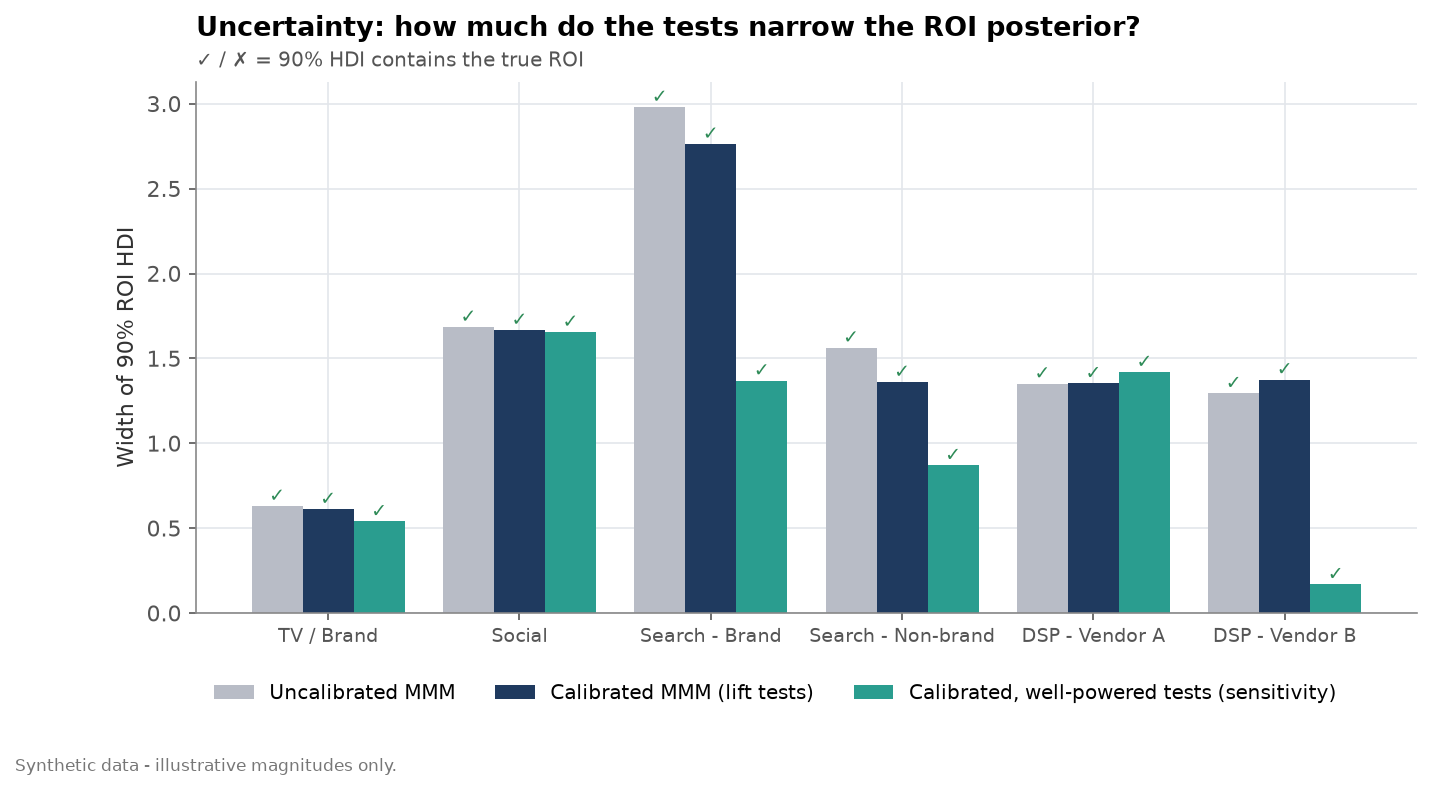

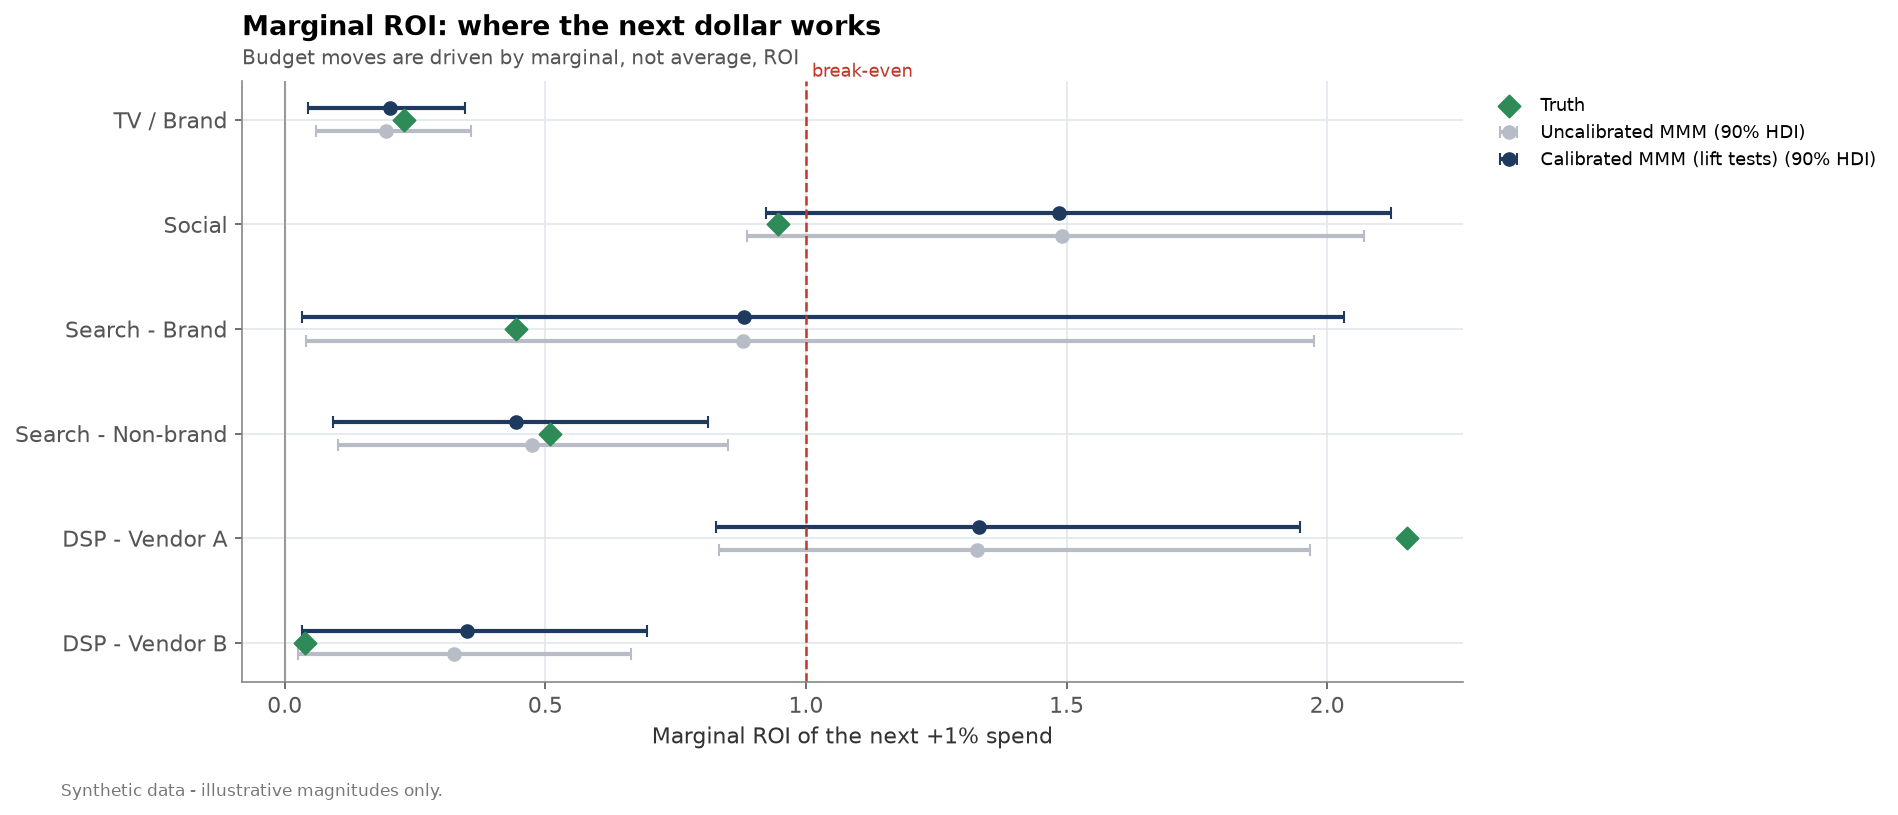

In [7]:
h = report._headline(S)
print(f"Mean |ROI error|  uncalibrated {h['roi_mae_uncalibrated']:.2f}  ->  calibrated {h['roi_mae_calibrated']:.2f}"
      + (f"  (sensitivity, well-powered tests: {h['roi_mae_calibrated_powered_sensitivity']:.2f})" if 'roi_mae_calibrated_powered_sensitivity' in h else ""))
print("channels improved by calibration:", h["channels_improved_by_calibration"])
for f in ("04_roi_forest", "05_roi_error", "16_uncertainty_width", "06_marginal_roi"):
    display(Image(FIG + f + ".png"))

### Reading this honestly

Four of the five tests were designed and powered on **quote starts**; bound sales are a small, noisy fraction of quotes,
so at the sales stage their readouts are statistically indistinguishable from zero and some land on the wrong side of their
own geo truth (the all-search arm even reads a *negative* sales effect). Only DSP Vendor A was sized for sales (by its own
pre-period power ladder), and its likelihood term moves its channel toward the truth. A correctly specified likelihood
moves the posterior only a little for the noisy tests, and where it moves it, it moves it toward the noisy readout, which
drags channels that share windows. So with the tests as actually read out, calibration does **not** reduce average ROI
error here; that is the honest result, printed above from the JSON.

The **sensitivity fit** feeds the same test designs (same channels, windows, leakage) with well-powered readouts (one simulated
draw at ±15% SE around the truth in the test geos). It isolates "is the calibration machinery right?" from "were the tests
informative?". Read its error next to the other two in the table above: whatever gap remains is *model-side* (a 6-12 week,
geo-local, test-spend-level return maps only partly onto a 3-year national ROI), not test-side. Calibration is necessary, not
sufficient: the next tests should be powered on sales **and** run long enough / at realistic spend so that the likelihood term
measures the quantity the MMM needs.

## 4. Response curves, carry-over, and contributions

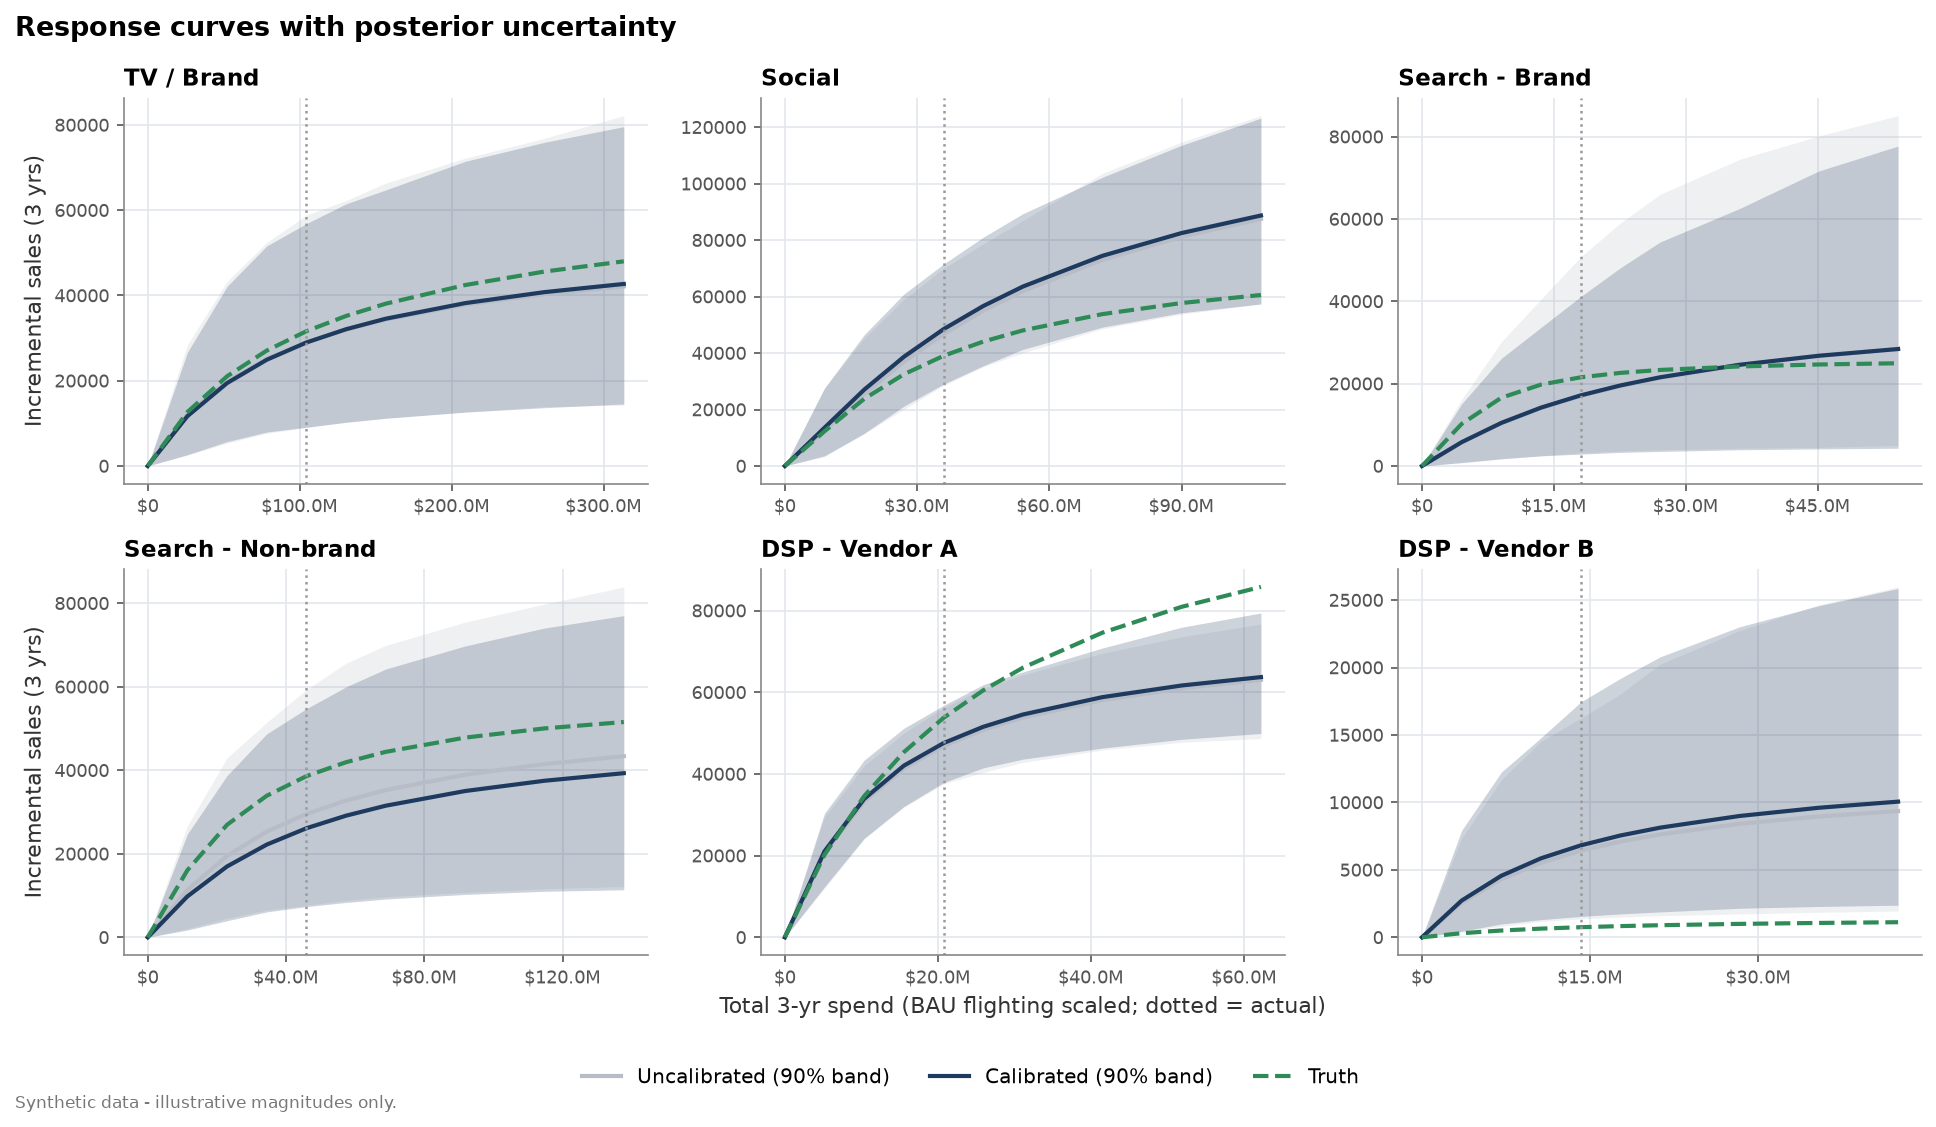

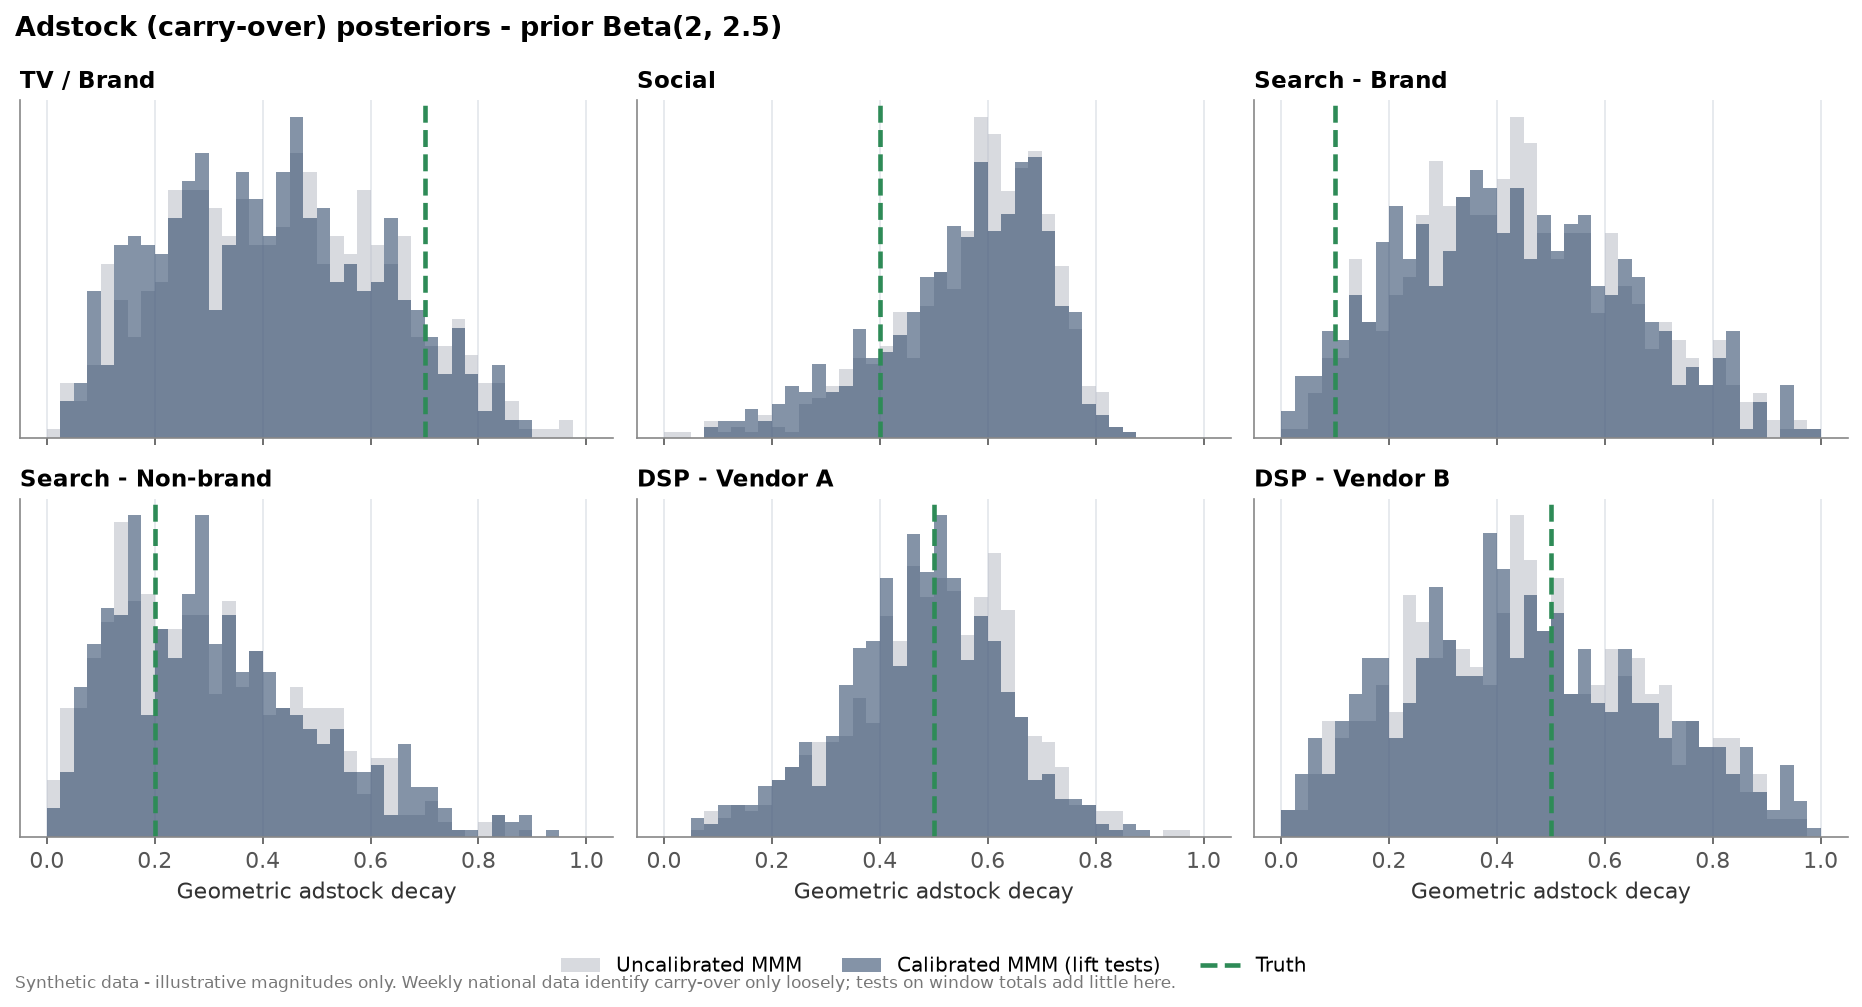

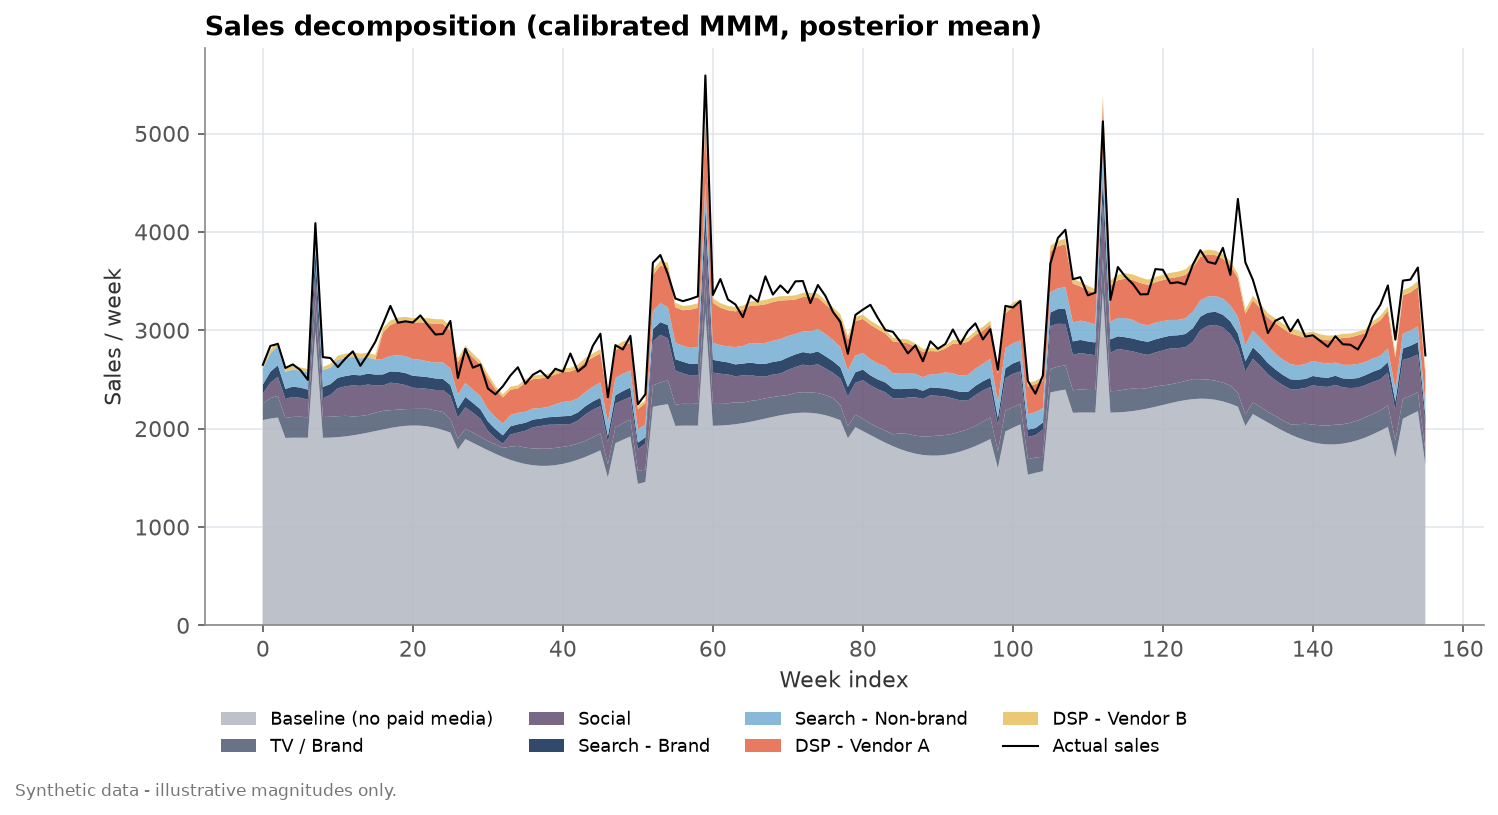

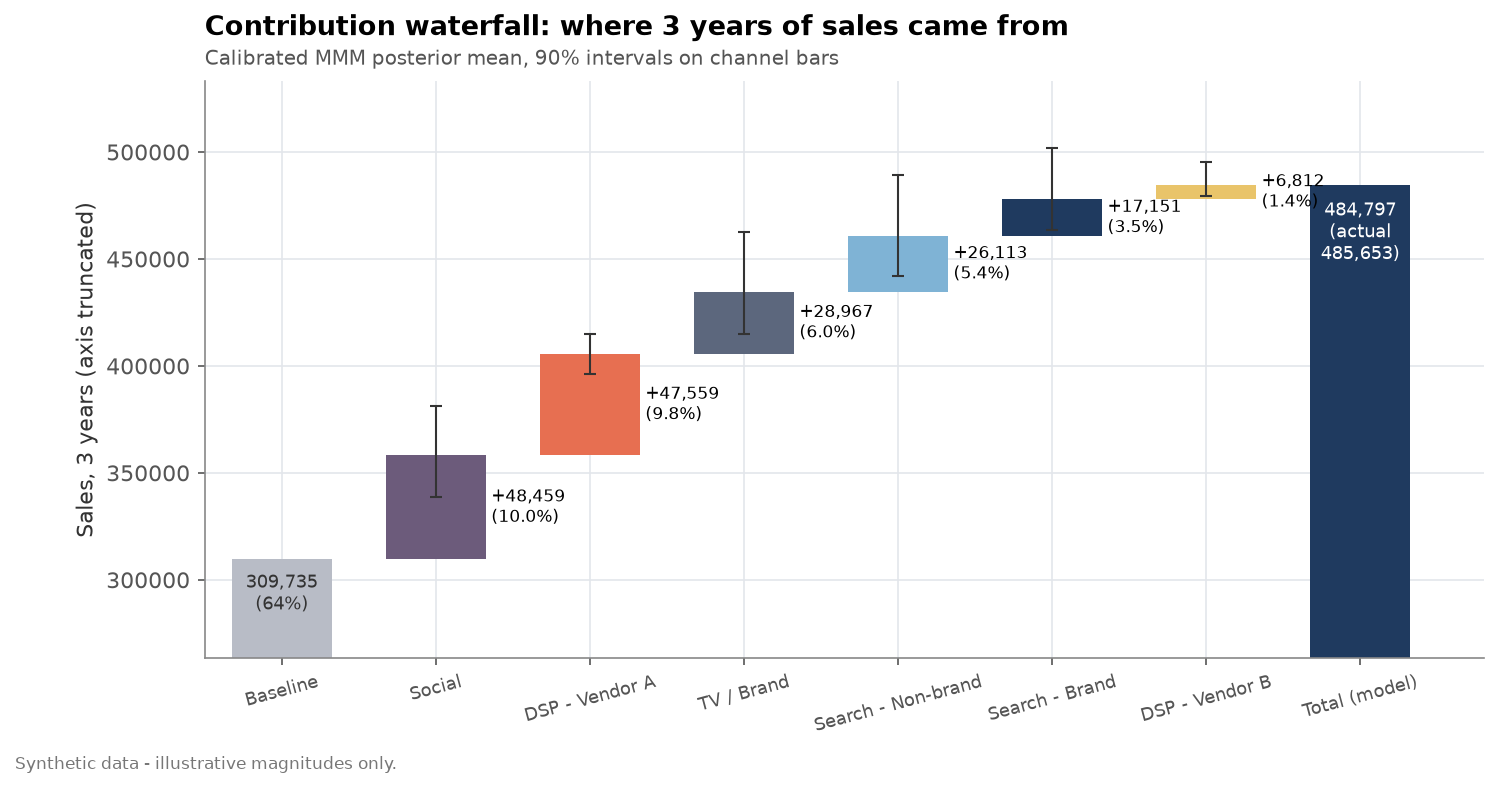

In [8]:
for f in ("07_response_curves", "08_adstock_posteriors", "09_contribution_area", "10_contribution_waterfall"):
    display(Image(FIG + f + ".png"))

## 5. Triangulation: five answers to "what does this channel return?"

Last-touch is biased in both directions (credits Vendor B and branded search far above their incremental value, gives TV nothing).
Single experiments are unbiased but local and noisy. The MMM is national and cross-channel but needs the tests to anchor it.

,channel,last_touch_roi,experiment_roi,experiment_roi_se,uncalibrated_roi,calibrated_roi,true_roi
0,tv,0.00,NaN,NaN,0.42,0.42,0.45
1,social,1.30,2.65,4.48,1.95,2.02,1.63
2,search_brand,2.99,2.47,5.59,1.41,1.43,1.79
3,search_nonbrand,1.38,-1.58,2.72,0.97,0.85,1.26
4,dsp_a,3.17,3.78,1.30,3.39,3.44,3.89
5,dsp_b,4.12,4.66,4.95,0.68,0.72,0.08


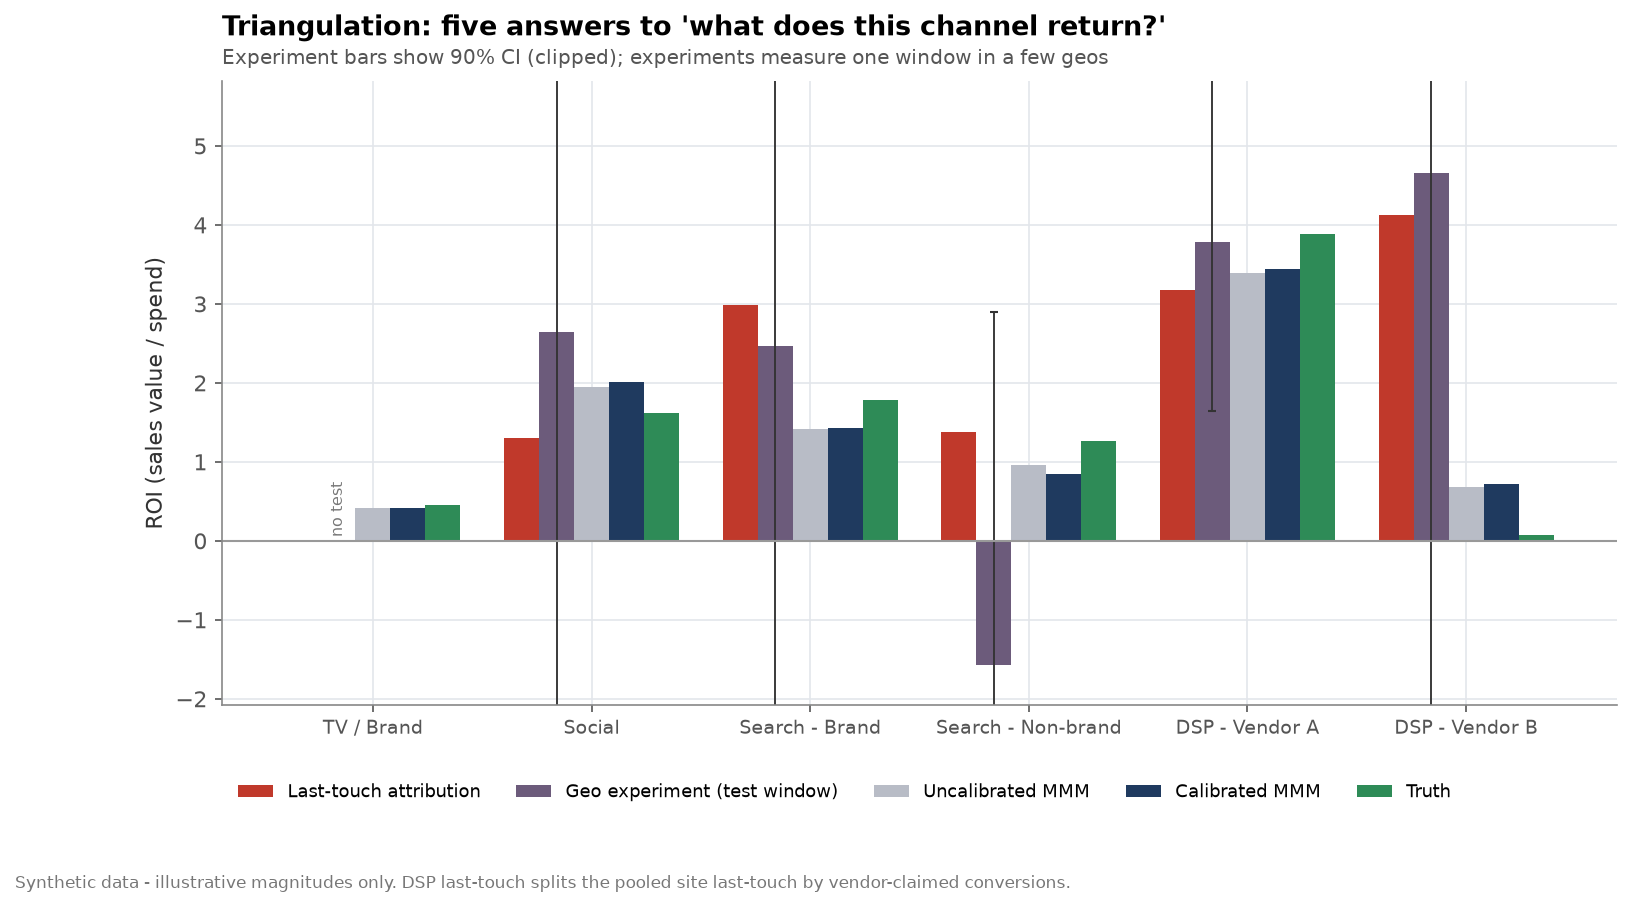

In [9]:
display(triangulation_table(S).drop(columns=["experiment_source"]).round(2)); display(Image(FIG + "11_triangulation.png"))

## 6. Budget optimizer (posterior-aware)

Plan = replay the last 52 weeks' flighting with each channel's level scaled by m_c ∈ [0.7, 1.3], total fixed. SLSQP maximises the
posterior-**mean** incremental sales; every plan is then evaluated over all posterior draws (HDI, P(better), CPA). Because this is a
simulator we can also score each plan against the **true** response.

In [10]:
o = S.optimizer["calibrated"]
mix = pd.DataFrame({"status_quo": o["status_quo"]["spend_by_channel"], "calibrated_opt": o["optimal"]["spend_by_channel"],
                    "uncalibrated_opt": S.optimizer["uncalibrated"]["optimal"]["spend_by_channel"]})
mix["change"] = mix.calibrated_opt / mix.status_quo - 1
display(mix.round(3))
d = o["optimal"]["delta_vs_ref"]
print(f"Expected gain {d['mean']:+,.0f} sales/yr (90% HDI {d['hdi_low']:,.0f} to {d['hdi_high']:,.0f}), P(better) {o['optimal']['prob_better']:.1%}")
print(f"CPA ${o['status_quo']['cpa']['mean']:,.0f} -> ${o['optimal']['cpa']['mean']:,.0f}")
for n, r in S.optimizer.items():
    if r.get("truth_check"):
        print(f"{n:>20s} plan: TRUE gain {r['truth_check']['true_gain']:+,.0f} sales ({r['truth_check']['true_gain_pct']:+.1%})")

,status_quo,calibrated_opt,uncalibrated_opt,change
tv,3.225245e+07,2.257671e+07,2.257671e+07,-0.300
social,1.477374e+07,1.920586e+07,1.920586e+07,0.300
search_brand,6.225161e+06,8.092710e+06,8.092710e+06,0.300
search_nonbrand,1.296510e+07,1.571938e+07,1.571938e+07,0.212
dsp_a,7.416025e+06,9.640833e+06,9.640833e+06,0.300
dsp_b,5.343431e+06,3.740401e+06,3.740401e+06,-0.300


Expected gain +5,186 sales/yr (90% HDI 2,016 to 8,400), P(better) 99.5%
CPA $1,214 -> $1,126
        uncalibrated plan: TRUE gain +4,718 sales (+6.9%)
          calibrated plan: TRUE gain +4,718 sales (+6.9%)
  calibrated_powered plan: TRUE gain +4,718 sales (+6.9%)


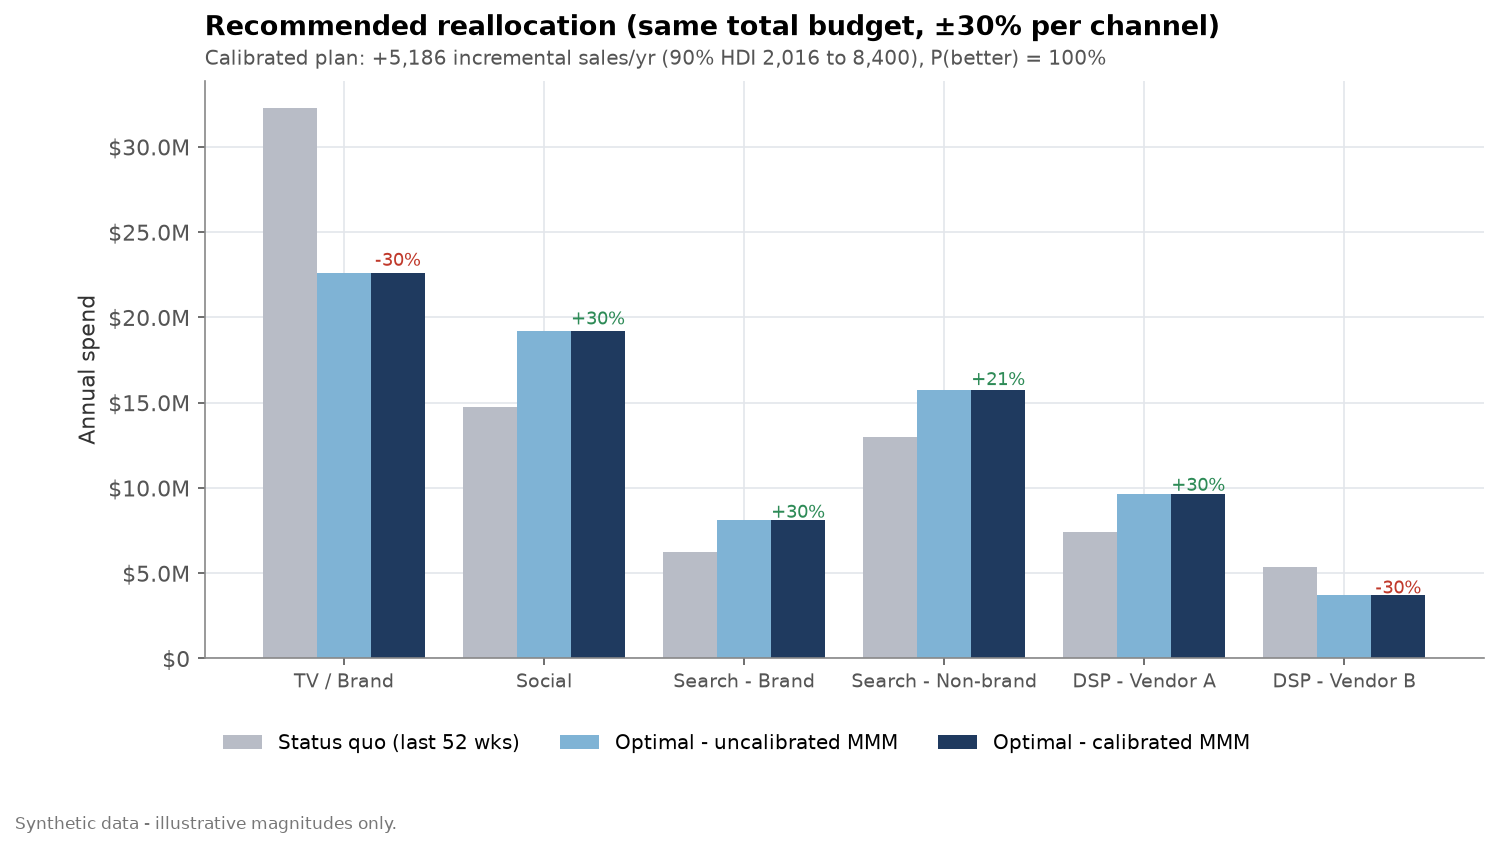

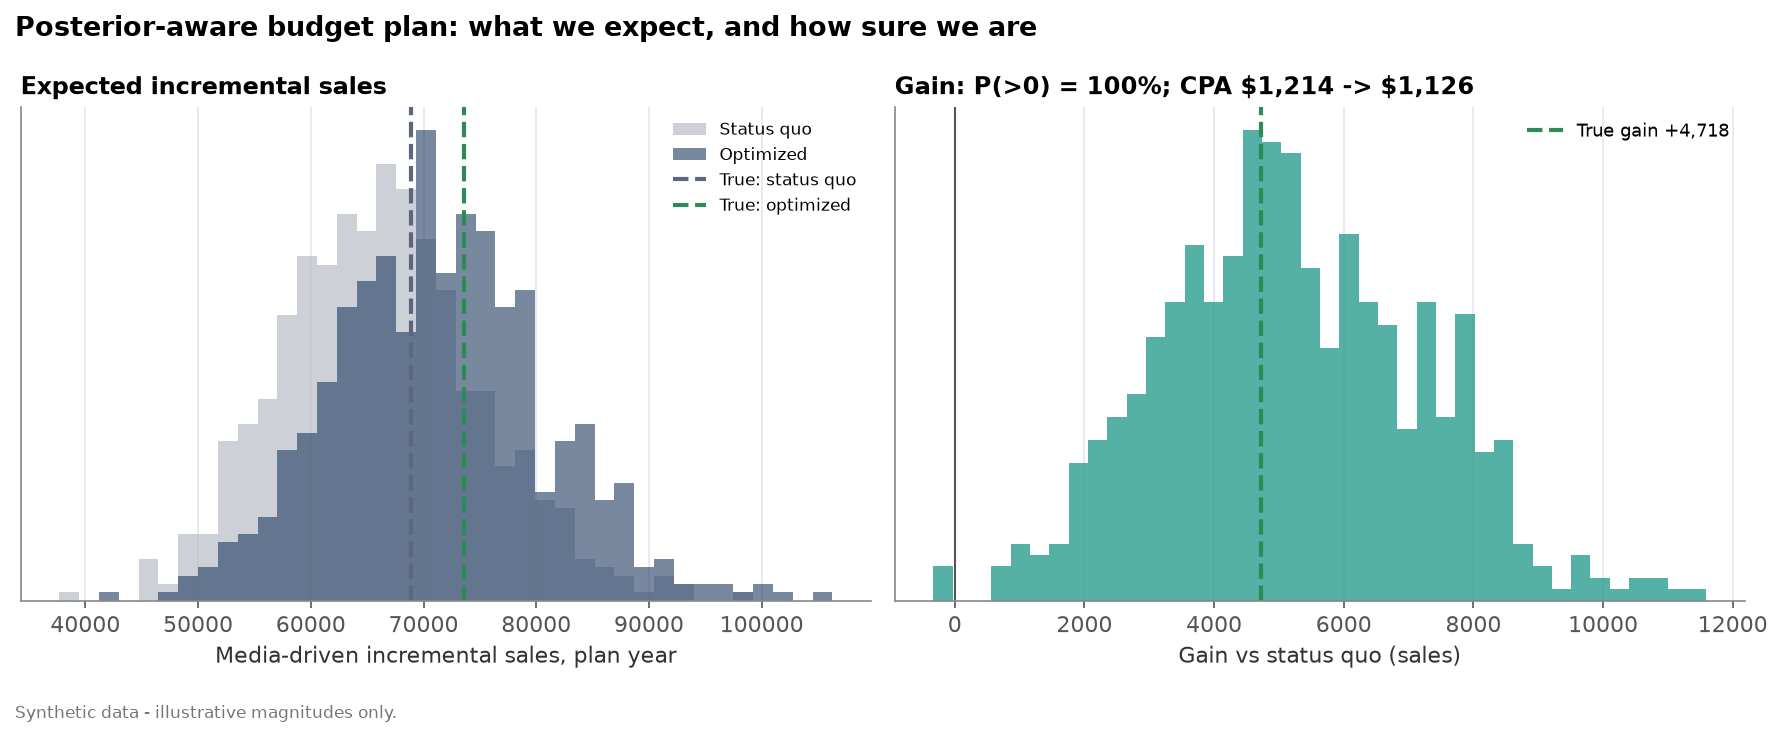

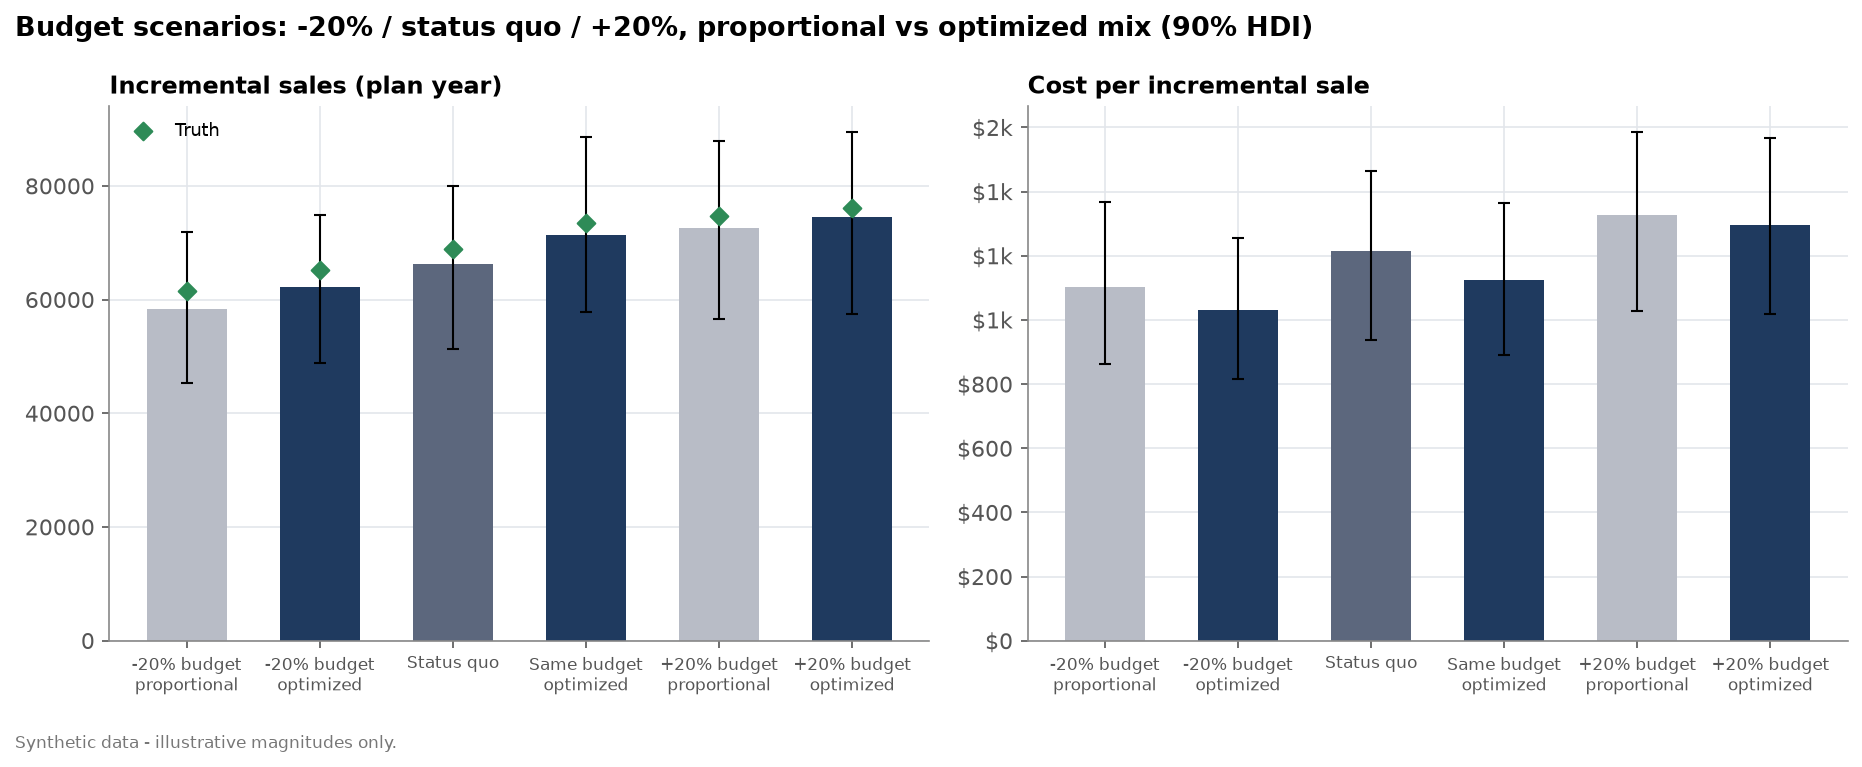

In [11]:
for f in ("12_optimizer_mix", "13_optimizer_outcome", "14_budget_scenarios"):
    display(Image(FIG + f + ".png"))

The direction of the reallocation (cut TV and DSP Vendor B; add Social, DSP Vendor A and search) is robust across all three
fits, which is why the weakly-calibrated plan earns almost the same true gain as the others (see the TRUE gain lines above). Calibration matters most for
*how far* to move money and for channels whose ROI posterior straddles break-even — which is what the next test should target.

## 7. Next test: value of information

EVPPI per channel: split the posterior into ROI quartiles for that channel, re-optimise within each, and average the gain over the
current optimum. A wide posterior only matters if resolving it would move money.

,evppi_sales,evppi_value,roi_cv,roi_hdi_width
search_brand,135.860,203789.554,0.792,2.763
search_nonbrand,96.162,144243.393,0.569,1.360
dsp_b,74.984,112476.407,0.790,1.376
dsp_a,7.309,10962.929,0.129,1.353
tv,5.832,8748.068,0.508,0.612
social,0.661,991.703,0.285,1.667


Recommended next test: search_brand


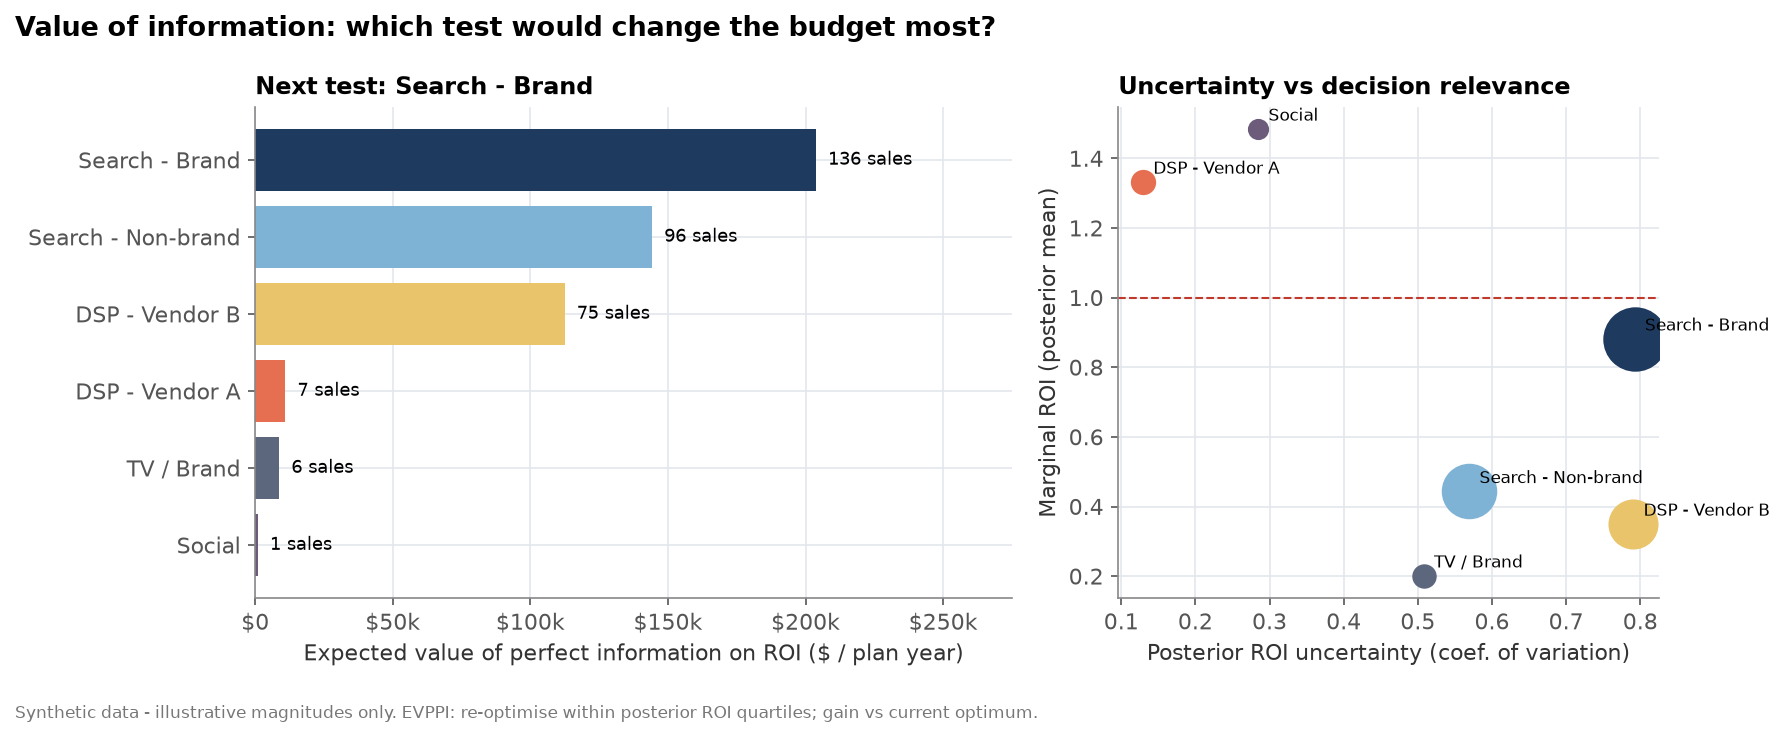

In [12]:
voi = pd.DataFrame(S.voi).T.sort_values("evppi_value", ascending=False)
display(voi.round(3)); print("Recommended next test:", voi.index[0])
display(Image(FIG + "15_value_of_information.png"))

## 8. Write outputs

Same artefacts as `python -m incrlab.mmm`: figures, `reports/results/mmm.json`, `reports/readouts/mmm.md`.

In [13]:
S.figures = F.make_all(S)
from incrlab.config import REPO_ROOT
for _p in (report.write_results_json(S), report.write_readout_md(S)):
    print(_p.relative_to(REPO_ROOT)); print(len(S.figures), "figures")

reports/results/mmm.json
16 figures
reports/readouts/mmm.md
16 figures


## Caveats
- The simulator's response family matches the model's (adstock + Hill); real MMMs also face misspecification.
- ~150 weekly national points for ~35 parameters: priors matter; they are identical across channels (shown above).
- Geo tests are local; the 10% transport term and window-level likelihood are deliberate hedges.
- The lesson for the measurement program: **power the next tests on the decision metric** (sales), or calibrate on the funnel stage the tests can actually see.